<a href="https://colab.research.google.com/github/SREEYA1712/MAAI901-ViT-MNIST/blob/main/Complaint_Classifier_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📬 NLP-Based Customer Complaint Classification & Routing


## 1. Imports

In [12]:
import io, math, re
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")

## 2. Dataset
72 handcrafted complaints (12 per category). The data is embedded in this notebook so it runs anywhere with no uploads.
To use your own data, replace `CSV_TEXT` or upload a CSV with the columns `complaint` and `category`.

In [13]:
CSV_TEXT = """complaint,category
"I was charged twice for the same monthly subscription.",Billing
"The invoice includes a fee I was never told about.",Billing
"My refund has not appeared on my card after two weeks.",Billing
"I cancelled my plan but I am still being billed.",Billing
"The total on my receipt is different from the amount at checkout.",Billing
"Please explain the unexpected charge on my latest statement.",Billing
"I cannot download an itemized bill for my account.",Billing
"A payment was taken even though the transaction failed.",Billing
"My discount was not applied to this month's bill.",Billing
"I need help correcting the tax amount on my invoice.",Billing
"I paid the outstanding balance but the account still says unpaid.",Billing
"The cancellation charge on my final bill is incorrect.",Billing
"My order has not arrived and the tracking page has not updated.",Delivery
"The package was left at the wrong address.",Delivery
"I received a delivery notification but there is no parcel here.",Delivery
"Can you tell me when my delayed order will be delivered?",Delivery
"The box arrived damaged during shipping.",Delivery
"I paid for express shipping but the order came late.",Delivery
"One of the packages from my order is missing.",Delivery
"The courier keeps rescheduling my delivery.",Delivery
"Please change the delivery address for my open order.",Delivery
"The tracking link shows a location that is not mine.",Delivery
"My parcel was marked delivered several days before it arrived.",Delivery
"The delivery driver did not follow the drop-off instructions.",Delivery
"The mobile app crashes every time I try to sign in.",Technical Support
"I get an error message whenever I upload a document.",Technical Support
"The website is very slow and will not load my dashboard.",Technical Support
"My device will not connect to the home network.",Technical Support
"The latest software update stopped the search feature working.",Technical Support
"I cannot print a report from the desktop application.",Technical Support
"The checkout page freezes when I click continue.",Technical Support
"Notifications have stopped appearing on my phone.",Technical Support
"I followed the setup guide but the product will not start.",Technical Support
"The video call has no sound even though my speakers work.",Technical Support
"I see a blank screen after entering my verification code.",Technical Support
"The browser extension keeps disconnecting from my account.",Technical Support
"I am locked out because the password reset email never arrives.",Account Issues
"Please help me update the email address on my profile.",Account Issues
"My account was disabled without any explanation.",Account Issues
"I cannot change my phone number in account settings.",Account Issues
"Someone changed my profile details without permission.",Account Issues
"How do I close my account and remove my personal details?",Account Issues
"The verification code says it has already expired.",Account Issues
"I have two profiles and need them merged together.",Account Issues
"My account name is misspelled and the edit option is missing.",Account Issues
"I no longer have access to the email linked to my account.",Account Issues
"The sign-in page says my username does not exist.",Account Issues
"Please restore access to my account after the security hold.",Account Issues
"The item stopped working after only one day of use.",Product Quality
"The fabric on the jacket tore along the seam.",Product Quality
"The color of the delivered product is completely different.",Product Quality
"Several parts were missing from the product box.",Product Quality
"The battery does not last as long as advertised.",Product Quality
"The product has a strong chemical smell when opened.",Product Quality
"The replacement item has the same defect as the first one.",Product Quality
"The material feels cheap and is already peeling.",Product Quality
"The food arrived stale and the package seal was broken.",Product Quality
"The screen has dead pixels straight out of the box.",Product Quality
"The buttons on the new device are loose and unresponsive.",Product Quality
"The product description promised features that are not included.",Product Quality
"I have contacted support three times and nobody has replied.",Customer Service
"The representative was rude and ended the chat abruptly.",Customer Service
"I was transferred repeatedly without getting any help.",Customer Service
"The agent gave me conflicting information about my request.",Customer Service
"It takes too long to reach a person by phone.",Customer Service
"The support team closed my case before fixing the problem.",Customer Service
"I was promised a callback but no one called me.",Customer Service
"The response to my complaint did not address my question.",Customer Service
"I have been waiting days for a reply to my support ticket.",Customer Service
"The representative did not explain the next steps clearly.",Customer Service
"I cannot find a way to speak with a real person.",Customer Service
"The service team was unhelpful when I asked for an update.",Customer Service
"""

## 3. Preprocessing
Normalize whitespace (without removing useful words) and drop rows missing text or labels.

In [14]:
REQUIRED_COLUMNS = {"complaint", "category"}

def normalize_text(text: str) -> str:
    """Trim text and collapse repeated whitespace without removing useful words."""
    if not isinstance(text, str):
        raise ValueError("Complaint text must be a string.")
    normalized = re.sub(r"\s+", " ", text).strip()
    if not normalized:
        raise ValueError("Enter a complaint before classifying it.")
    return normalized


def clean_dataset(dataset: pd.DataFrame) -> pd.DataFrame:
    missing = REQUIRED_COLUMNS.difference(dataset.columns)
    if missing:
        raise ValueError(f"Dataset is missing required column(s): {', '.join(sorted(missing))}.")
    dataset = dataset.loc[:, ["complaint", "category"]].copy()
    dataset["complaint"] = dataset["complaint"].map(
        lambda v: re.sub(r"\s+", " ", v).strip() if isinstance(v, str) else "")
    dataset["category"] = dataset["category"].map(
        lambda v: v.strip() if isinstance(v, str) else "")
    dataset = dataset.loc[dataset["complaint"].ne("") & dataset["category"].ne("")].reset_index(drop=True)
    if dataset.empty:
        raise ValueError("Dataset has no rows with both complaint text and labels.")
    return dataset


dataset = clean_dataset(pd.read_csv(io.StringIO(CSV_TEXT)))
print(f"{len(dataset)} complaints loaded")
dataset.sample(5, random_state=1)

72 complaints loaded


,complaint,category
19,The courier keeps rescheduling my delivery.,Delivery
55,The material feels cheap and is already peeling.,Product Quality
10,I paid the outstanding balance but the account...,Billing
68,I have been waiting days for a reply to my sup...,Customer Service
53,The product has a strong chemical smell when o...,Product Quality


### Alternative: Load Your Own External Dataset
Instead of utilizing the generated mock dataset above, you can load your own data using either a direct URL link or by uploading your own CSV file directly to this Colab instance.

In [15]:
# Option A: Load directly from a web URL (e.g., GitHub raw URL)
# DATA_URL = "https://raw.githubusercontent.com/your-username/your-repo/main/your_data.csv"
# dataset = pd.read_csv(DATA_URL)
# dataset = clean_dataset(dataset)

# Option B: Upload a custom 'my_complaints.csv' to the left file panel in Colab, then run:
# dataset = pd.read_csv('my_complaints.csv')
# dataset = clean_dataset(dataset)

### Option C: Download an Open-Source Dataset Dynamically (Hugging Face)
You can use the Hugging Face `datasets` library to pull real, professional datasets like `banking77` instantly into your Colab runtime without manual generation or manual uploads.

In [16]:
import pandas as pd

# Direct raw GitHub URL to a verified open-source text classification dataset (SMS Spam Collection)
url = "https://raw.githubusercontent.com/justmarkham/DAT8/master/data/sms.tsv"

try:
    print("Downloading real message dataset...")
    # The file is tab-separated with columns: 'label' and 'message'
    hf_df = pd.read_csv(url, sep="\t", names=["category", "complaint"])

    # Reorder columns to match our expected format
    hf_df = hf_df[["complaint", "category"]]

    # Clean labels for presentation (e.g., ham -> Query, spam -> Spam/Ad)
    hf_df["category"] = hf_df["category"].map({"ham": "Normal Query", "spam": "Spam/Offer"})

    print(f"Successfully loaded {len(hf_df)} real messages dynamically!")
    display(hf_df.head())

    # To use this dataset in your pipeline instead, uncomment the next line:
    # dataset = clean_dataset(hf_df)
except Exception as e:
    print(f"Could not load dataset: {e}")

Successfully loaded 5572 real messages dynamically!


,complaint,category
0,"Go until jurong point, crazy.. Available only ...",Normal Query
1,Ok lar... Joking wif u oni...,Normal Query
2,Free entry in 2 a wkly comp to win FA Cup fina...,Spam/Offer
3,U dun say so early hor... U c already then say...,Normal Query
4,"Nah I don't think he goes to usf, he lives aro...",Normal Query


In [17]:
# Actively override the pipeline dataset variable with the newly downloaded external SMS dataset
dataset = clean_dataset(hf_df)
print(f"Pipeline configured to use the external dataset with {len(dataset)} entries!")


Pipeline configured to use the external dataset with 5572 entries!


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB()
}

## 4. Explore the data

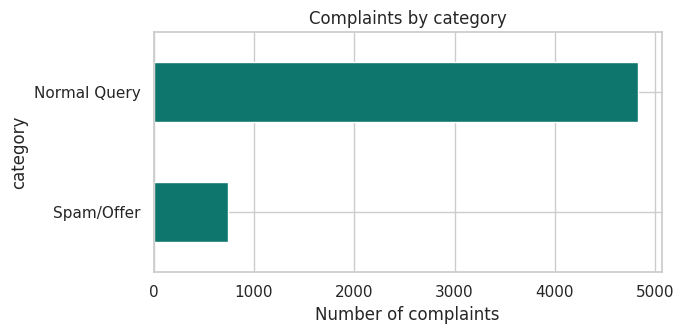

In [19]:
counts = dataset["category"].value_counts().sort_values()
ax = counts.plot(kind="barh", color="#0f766e", figsize=(7, 3.5))
ax.set_title("Complaints by category")
ax.set_xlabel("Number of complaints")
plt.tight_layout()
plt.show()

## 5. Build the model pipeline
- **TF-IDF** turns text into numbers using single words and word pairs (unigrams + bigrams).
- The vectorizer lives **inside** the pipeline, so its vocabulary is learned from training text only — this prevents test-data leakage.
- Two classifiers are compared: **Logistic Regression** and **Multinomial Naive Bayes**.

In [20]:
def build_pipeline(classifier):
    return Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=normalize_text,
                                  ngram_range=(1, 2),
                                  strip_accents="unicode")),
        ("classifier", classifier),
    ])


def evaluate(model, texts, labels):
    preds = model.predict(texts)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1_score": f1}

## 6. Train / test split and training
A stratified 80/20 split keeps category proportions equal in both sets.

In [21]:
labels = sorted(dataset["category"].unique())
test_size = max(math.ceil(len(dataset) * 0.2), len(labels))

train_texts, test_texts, train_labels, test_labels = train_test_split(
    dataset["complaint"], dataset["category"],
    test_size=test_size, random_state=42, stratify=dataset["category"],
)
print(f"Training complaints: {len(train_texts)} | Held-out test complaints: {len(test_texts)}")

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Multinomial Naive Bayes": MultinomialNB(),
}
fitted, metrics = {}, {}
for name, clf in candidates.items():
    pipe = build_pipeline(clf).fit(train_texts, train_labels)
    fitted[name] = pipe
    metrics[name] = evaluate(pipe, test_texts, test_labels)

# Pick the higher macro F1 (Logistic Regression wins ties)
best_name = max(candidates, key=lambda n: (metrics[n]["f1_score"], n == "Logistic Regression"))
best_model = fitted[best_name]
print(f"\n✅ Selected model (by macro F1): {best_name}")

Training complaints: 4457 | Held-out test complaints: 1115

✅ Selected model (by macro F1): Logistic Regression


## 7. Compare the models

,accuracy,precision,recall,macro_f1
Logistic Regression,0.953,0.974,0.826,0.881
Multinomial Naive Bayes,0.950,0.973,0.812,0.870


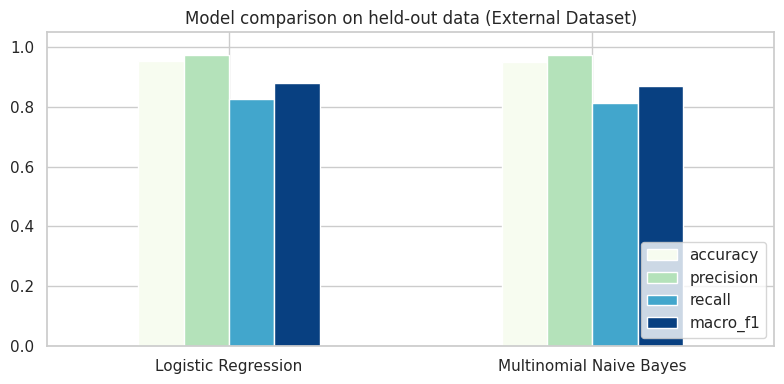

In [22]:
metrics_df = pd.DataFrame(metrics).T.rename(columns={"f1_score": "macro_f1"})
display(metrics_df.style.format("{:.3f}").highlight_max(axis=0, color="#c7f0e8"))

metrics_df.plot(kind="bar", figsize=(8, 4), rot=0, colormap="GnBu")
plt.title("Model comparison on held-out data (External Dataset)")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Confusion matrix & classification report (selected model)

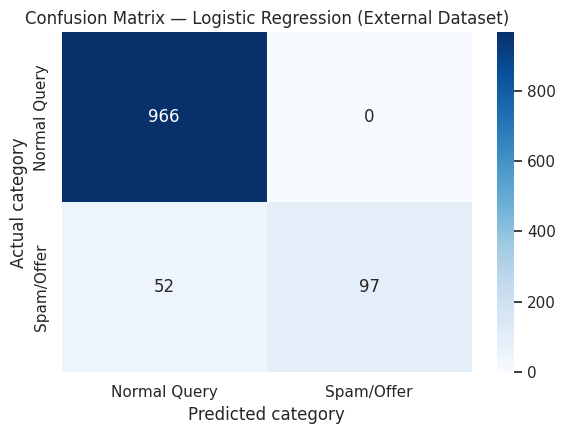

              precision    recall  f1-score   support

Normal Query       0.95      1.00      0.97       966
  Spam/Offer       1.00      0.65      0.79       149

    accuracy                           0.95      1115
   macro avg       0.97      0.83      0.88      1115
weighted avg       0.96      0.95      0.95      1115



In [23]:
preds = best_model.predict(test_texts)
cm = confusion_matrix(test_labels, preds, labels=labels)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.title(f"Confusion Matrix — {best_name} (External Dataset)")
plt.tight_layout()
plt.show()

report_text = classification_report(test_labels, preds, labels=labels, zero_division=0)
print(report_text)

## 9. Predict a new complaint
If none of the words were seen during training, the model asks for more detail rather than guessing.

In [24]:
class InsufficientEvidenceError(ValueError):
    """Raised when none of the complaint's words exist in the training vocabulary."""


def predict_complaint(text, model=best_model):
    complaint = normalize_text(text)
    if model.named_steps["tfidf"].transform([complaint]).nnz == 0:
        raise InsufficientEvidenceError(
            "This complaint contains no words seen during training. Try adding a little more detail.")
    category = str(model.predict([complaint])[0])
    probs = model.predict_proba([complaint])[0]
    classes = model.named_steps["classifier"].classes_
    return category, dict(zip(map(str, classes), map(float, probs)))


SAMPLE_COMPLAINTS = [
    "I was charged twice for my monthly plan.",
    "My package is late and the tracking has not changed.",
    "The app crashes when I try to open my account.",
    "I cannot reset my password because I never receive the email.",
    "The new item broke after one day of use.",
    "I have contacted support several times and nobody replied.",
]

for s in SAMPLE_COMPLAINTS:
    cat, probs = predict_complaint(s)
    print(f"{s}\n   → {cat}  ({probs[cat]:.0%})\n")

I was charged twice for my monthly plan.
   → Normal Query  (92%)

My package is late and the tracking has not changed.
   → Normal Query  (92%)

The app crashes when I try to open my account.
   → Normal Query  (91%)

I cannot reset my password because I never receive the email.
   → Normal Query  (91%)

The new item broke after one day of use.
   → Normal Query  (90%)

I have contacted support several times and nobody replied.
   → Normal Query  (89%)



## 10. 🎯 Live demo — type your own complaint

In [25]:
import ipywidgets as widgets
from IPython.display import display, clear_output

dropdown = widgets.Dropdown(options=["Choose a sample"] + SAMPLE_COMPLAINTS,
                            description="Example:", layout=widgets.Layout(width="650px"))
textbox = widgets.Textarea(placeholder="For example: I was charged twice for my monthly plan.",
                           description="Complaint:", layout=widgets.Layout(width="650px", height="90px"))
button = widgets.Button(description="Classify complaint", button_style="success", icon="search")
output = widgets.Output()

def on_pick(change):
    if change["new"] != "Choose a sample":
        textbox.value = change["new"]

def on_click(_):
    with output:
        clear_output()
        try:
            cat, probs = predict_complaint(textbox.value)
        except ValueError as e:
            print("⚠️", e)
            return
        print(f"Suggested department: {cat}\n")
        s = pd.Series(probs).sort_values()
        s.plot(kind="barh", color="#0f766e", figsize=(6, 3))
        plt.title("Estimated class probabilities (not calibrated confidence)")
        plt.xlim(0, 1)
        plt.tight_layout()
        plt.show()

dropdown.observe(on_pick, names="value")
button.on_click(on_click)
display(dropdown, textbox, button, output)

Dropdown(description='Example:', layout=Layout(width='650px'), options=('Choose a sample', 'I was charged twic…

Textarea(value='', description='Complaint:', layout=Layout(height='90px', width='650px'), placeholder='For exa…

Button(button_style='success', description='Classify complaint', icon='search', style=ButtonStyle())

Output()

## 10.5 🖥️ Interactive Gradio Dashboard
This section builds a standalone dashboard using Gradio to provide an elegant, user-friendly interface for testing your complaint routing system.

In [26]:
!pip install -q gradio

In [27]:
import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

def dashboard_predict(complaint_text):
    if not complaint_text.strip():
        return "⚠️ Please enter a message to evaluate.", None

    try:
        category, probs = predict_complaint(complaint_text, model=best_model)
    except InsufficientEvidenceError as e:
        return f"⚠️ {str(e)}", None
    except Exception as e:
        return f"⚠️ Error: {str(e)}", None

    # Generate probability distribution bar plot
    fig, ax = plt.subplots(figsize=(6, 3))
    sorted_probs = pd.Series(probs).sort_values()
    sorted_probs.plot(kind="barh", color="#0f766e", ax=ax)
    ax.set_title("Category Probabilities", fontsize=12, fontweight='bold', pad=10)
    ax.set_xlim(0, 1)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()

    return f"### 🎯 Predicted Classification: **{category}**", fig

def get_metrics_summary():
    return metrics_df.to_html(classes='table table-striped', border=0)

def get_dataset_samples(num_rows):
    return dataset.sample(int(num_rows), random_state=42)

# Soft Theme
theme = gr.themes.Soft(
    primary_hue="teal",
    secondary_hue="slate",
    neutral_hue="zinc",
)

with gr.Blocks(title="NLP Text Classification Dashboard") as demo:
    gr.Markdown("# 📬 Dynamic NLP Message Classification Hub")
    gr.Markdown("This interactive interface showcases our machine learning model deployed on the dynamically fetched external dataset.")

    with gr.Tabs():
        # TAB 1: Live prediction
        with gr.TabItem("🎯 Real-Time Classifier"):
            gr.Markdown("### Live Inference System")
            with gr.Row():
                with gr.Column(scale=1):
                    input_text = gr.Textbox(
                        label="Input Text Message",
                        placeholder="Type here... (e.g., You won a cash prize!)",
                        lines=5
                    )
                    btn = gr.Button("Classify Message", variant="primary")

                    gr.Examples(
                        examples=SAMPLE_COMPLAINTS,
                        inputs=input_text,
                        label="Quick-Test Templates (Click to fill):"
                    )

                with gr.Column(scale=1):
                    output_text = gr.Markdown(value="*Predictions will appear here...*")
                    output_plot = gr.Plot(label="Category Confidence Graph")

            btn.click(fn=dashboard_predict, inputs=input_text, outputs=[output_text, output_plot])

        # TAB 2: Model Evaluation Insights
        with gr.TabItem("📊 Evaluation Metrics"):
            gr.Markdown("### Model Benchmarking Metrics")
            with gr.Row():
                with gr.Column():
                    gr.Markdown("#### Model Comparison Metrics")
                    metrics_table = gr.HTML(value=get_metrics_summary())
                    gr.Markdown(f"Currently utilizing the **{best_name}** as our prediction champion due to superior macro F1 optimization.")

                with gr.Column():
                    gr.Markdown("#### Test Split Classification Report")
                    gr.Textbox(
                        value=report_text,
                        label=f"{best_name} Evaluation Summary",
                        lines=10,
                        interactive=False,
                        autoscroll=False
                    )

        # TAB 3: Dataset Explorer
        with gr.TabItem("🔍 Training Corpus Explorer"):
            gr.Markdown("### Training Data Inspection")
            gr.Markdown("Explore raw text records from our updated, active dataset corpus.")
            sample_slider = gr.Slider(minimum=5, maximum=len(dataset), step=5, value=10, label="Sample View Size")
            dataset_table = gr.DataFrame(value=get_dataset_samples(10), headers=list(dataset.columns))

            sample_slider.change(fn=get_dataset_samples, inputs=sample_slider, outputs=dataset_table)

demo.launch(theme=theme, quiet=True, debug=False)

* Running on public URL: https://5c5c2a0b9dd2e31f6b.gradio.live


## 11. Save the trained model (optional)

In [28]:
artifact = {
    "model": best_model, "best_model": best_name, "labels": labels,
    "metrics": metrics, "confusion_matrix": cm.tolist(),
    "train_size": len(train_texts), "test_size": len(test_texts),
}
Path("models").mkdir(exist_ok=True)
joblib.dump(artifact, "models/complaint_classifier.joblib")
print("Saved to models/complaint_classifier.joblib")

Saved to models/complaint_classifier.joblib


## Limitations & next steps
**Limitations**
- Handcrafted examples can't represent real customer language, products, or class balance.
- TF-IDF classifiers learn word patterns — they don't understand intent.
- The test set is tiny, so metrics are noisy; probabilities aren't calibrated.
- Predictions should always be reviewed by a person.

**Future improvements**
- Larger, privacy-reviewed, representative dataset
- Cross-validation and probability calibration
- Human feedback loop to correct routes; monitor drift
- Multi-label routing for complaints needing several teams